# Mini-Project 4: Rainfall Pattern & Crop Suitability Analyser

**Scenario.** An agricultural extension officer wants to compare rainfall regimes across regions and advise farmers
on which months suit which crops. Monthly rainfall is in **mm**, January to December (illustrative).

Reusable code: `src/rainfall.py`.

In [1]:
# --- Imports ----------------------------------------------------------------------

# math: built-in maths functions (we use math.cos only to show last year's mistake)
import math

# numpy: arrays and maths
import numpy as np

# pandas: tables
import pandas as pd

# matplotlib: charts; ListedColormap lets us choose our own heatmap colours
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# Our own code from src/rainfall.py
from src.rainfall import (
    MONTHS,                    # ["Jan", "Feb", ..., "Dec"]
    Region,                    # one region's rainfall
    CropRule,                  # a crop's good rainfall range
    DEFAULT_CROPS,             # maize, beans, banana rules
    cosine_similarity,         # our correct version
    cosine_similarity_scipy,   # scipy's version, for checking
    similarity_matrices,       # cosine / Pearson / Euclidean tables
    rainy_seasons,             # peak finder
    modality,                  # "unimodal" or "bimodal"
    load_nasa_power_csv,       # extension: real data loader
)

REGION_COLOURS = {"Kampala": "#2a78d6", "Gulu": "#eb6834", "Mbarara": "#1baf7a"}
INK = "#3b3a37"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

## Task 1 – The `Region` class

In [2]:
regions = [
    Region("Kampala", [120, 140, 180, 200, 220, 180,  90,  70,  60, 100, 110, 130]),
    Region("Gulu",    [  8,  25,  75, 160, 190, 145, 170, 215, 175, 150,  60,  15]),
    Region("Mbarara", [ 70,  85, 120, 140,  90,  25,  20,  55, 100, 125, 120,  90]),
]

pd.DataFrame([{
    "region": r.name,
    "annual total (mm)": r.annual_total(),
    "monthly mean (mm)": round(r.mean(), 1),
    "wettest month": r.wettest_month(),
    "driest month": r.driest_month(),
    "CV": round(r.coefficient_of_variation(), 3),
} for r in regions]).set_index("region")

,annual total (mm),monthly mean (mm),wettest month,driest month,CV
region,,,,,
Kampala,1600.0,133.3,May,Sep,0.388
Gulu,1388.0,115.7,Aug,Jan,0.642
Mbarara,1040.0,86.7,Apr,Jul,0.444


## Task 2 – The `CropRule` class and month-by-month suitability

**Where the thresholds come from.** The FAO *Crop Information* pages give each crop's water needs **per growing
season**: maize 500–800 mm (season of about 4 months), beans 300–500 mm (about 3 months), banana 1,200–2,200 mm per year.
We divided by the season length to get a **monthly** range. This is an approximation: real needs change during the
season (seedlings need less, flowering needs more).

Source: FAO Land & Water, *Crop Information* — https://www.fao.org/land-water/databases-and-software/crop-information/en/

In [3]:
crops = DEFAULT_CROPS          # maize, beans, banana
for rule in crops:
    print(rule, "| source:", rule.source)

CropRule('maize', 125-200 mm/month) | source: FAO Land & Water, Crop Information pages (fao.org/land-water/databases-and-software/crop-information): 500-800 mm over a ~4-month season
CropRule('beans', 100-165 mm/month) | source: FAO Land & Water, Crop Information pages (fao.org/land-water/databases-and-software/crop-information): 300-500 mm over a ~3-month season
CropRule('banana', 100-185 mm/month) | source: FAO Land & Water, Crop Information pages (fao.org/land-water/databases-and-software/crop-information): 1,200-2,200 mm per year


In [4]:
# One table per crop: rows = regions, columns = months, cells = label
for rule in crops:
    labels = pd.DataFrame([rule.classify_region(r) for r in regions],
                          index=[r.name for r in regions], columns=MONTHS)
    # Shorten the labels so the table fits: Good / Dry / Wet
    short = labels.replace({f"Good for {rule.crop}": "Good", "Drought risk": "Dry", "Waterlogging risk": "Wet"})
    print(f"\n=== {rule.crop.upper()} ({rule.min_mm}-{rule.max_mm} mm/month) ===")
    print(short.to_string())


=== MAIZE (125-200 mm/month) ===
         Jan   Feb   Mar   Apr   May   Jun   Jul  Aug   Sep   Oct  Nov   Dec
Kampala  Dry  Good  Good  Good   Wet  Good   Dry  Dry   Dry   Dry  Dry  Good
Gulu     Dry   Dry   Dry  Good  Good  Good  Good  Wet  Good  Good  Dry   Dry
Mbarara  Dry   Dry   Dry  Good   Dry   Dry   Dry  Dry   Dry  Good  Dry   Dry

=== BEANS (100-165 mm/month) ===
          Jan   Feb   Mar   Apr  May   Jun  Jul  Aug   Sep   Oct   Nov   Dec
Kampala  Good  Good   Wet   Wet  Wet   Wet  Dry  Dry   Dry  Good  Good  Good
Gulu      Dry   Dry   Dry  Good  Wet  Good  Wet  Wet   Wet  Good   Dry   Dry
Mbarara   Dry   Dry  Good  Good  Dry   Dry  Dry  Dry  Good  Good  Good   Dry

=== BANANA (100-185 mm/month) ===
          Jan   Feb   Mar   Apr  May   Jun   Jul  Aug   Sep   Oct   Nov   Dec
Kampala  Good  Good  Good   Wet  Wet  Good   Dry  Dry   Dry  Good  Good  Good
Gulu      Dry   Dry   Dry  Good  Wet  Good  Good  Wet  Good  Good   Dry   Dry
Mbarara   Dry   Dry  Good  Good  Dry   Dry   Dr

## Task 3 – Correcting last year's cosine similarity

Last year's question used `math.cos()`. That function returns the **cosine of an angle**, e.g. cos(0) = 1,
cos(π/2) = 0. It takes *one number* and knows nothing about vectors. **Cosine similarity** compares two whole
vectors a and b:

$$\text{cosine similarity}(a, b) = \frac{a \cdot b}{\lVert a \rVert \, \lVert b \rVert}$$

(dot product ÷ product of the lengths).

In [5]:
kampala, gulu, mbarara = regions

# The old mistake: math.cos of a single number, not a comparison of two regions
print("math.cos(120) =", round(math.cos(120), 4), "<- cosine of 120 radians, meaningless here")

# The correct method, checked against scipy
ours = cosine_similarity(kampala.rainfall, gulu.rainfall)
theirs = cosine_similarity_scipy(kampala.rainfall, gulu.rainfall)
print(f"Kampala vs Gulu - ours: {ours:.6f} | scipy: {theirs:.6f} | match: {np.isclose(ours, theirs)}")

math.cos(120) = 0.8142 <- cosine of 120 radians, meaningless here
Kampala vs Gulu - ours: 0.786609 | scipy: 0.786609 | match: True


## Task 4 – Three similarity / distance measures between every pair of regions

In [6]:
matrices = similarity_matrices(regions)
for name, table in matrices.items():
    print(f"\n=== {name} ===")
    print(table.round(3).to_string())


=== cosine ===
         Kampala   Gulu  Mbarara
Kampala    1.000  0.787    0.891
Gulu       0.787  1.000    0.749
Mbarara    0.891  0.749    1.000

=== pearson ===
         Kampala   Gulu  Mbarara
Kampala    1.000 -0.066    0.209
Gulu      -0.066  1.000   -0.174
Mbarara    0.209 -0.174    1.000

=== euclidean ===
         Kampala     Gulu  Mbarara
Kampala    0.000  315.268    250.4
Gulu     315.268    0.000    312.8
Mbarara  250.400  312.800      0.0


In [7]:
# Why cosine can call a dry and a wet region "similar": scale Kampala down to 30%
dry_kampala = Region("Dry Kampala", kampala.rainfall * 0.3)
print("Annual rain:", kampala.annual_total(), "mm vs", dry_kampala.annual_total(), "mm")
print("Cosine similarity:", round(cosine_similarity(kampala.rainfall, dry_kampala.rainfall), 3))
print("Euclidean distance:", round(float(np.linalg.norm(kampala.rainfall - dry_kampala.rainfall)), 1), "mm")

Annual rain: 1600.0 mm vs 480.0 mm
Cosine similarity: 1.0
Euclidean distance: 344.9 mm


**Why cosine can rate a much wetter region as "similar".** Cosine similarity only looks at the *direction* of the
12-month vector, which is the **shape** of the year (which months are relatively wet or dry), and ignores its *length*
(the total amount of rain). A region with exactly the same pattern but 30% of the rain scores a perfect **1.0**, even
though a crop that thrives in Kampala would fail there. **Pearson correlation** ignores both the size and the average
level. **Euclidean distance** is the measure that notices the amount, because it is measured in mm.
For crop advice you need both: the shape (when to plant) *and* the amount (whether there is enough water).

## Task 5 – Detecting rainy seasons with `scipy.signal.find_peaks`

A peak counts as a rainy season only if it stands at least **20 mm** above the surrounding dip (its *prominence*),
so small wiggles are ignored. The year is treated as a circle, so a December peak can be found.

In [8]:
KNOWN_CLIMATE = {   # the general pattern from Uganda's climate zones
    "Kampala": "bimodal (Mar-May and Sep-Nov) - Lake Victoria basin",
    "Gulu": "effectively unimodal (long season Apr-Oct) - northern Uganda",
    "Mbarara": "bimodal (Mar-May and Sep-Nov) - south-western Uganda",
}
season_rows = []
for r in regions:
    season_rows.append({
        "region": r.name,
        "peaks (20 mm prominence)": ", ".join(rainy_seasons(r, 20)),
        "our classification": modality(r, 20),
        "peaks (10 mm prominence)": ", ".join(rainy_seasons(r, 10)),
        "known climate": KNOWN_CLIMATE[r.name],
    })
pd.DataFrame(season_rows).set_index("region")

,peaks (20 mm prominence),our classification,peaks (10 mm prominence),known climate
region,,,,
Kampala,May,unimodal,"May, Dec",bimodal (Mar-May and Sep-Nov) - Lake Victoria ...
Gulu,"May, Aug",bimodal,"May, Aug",effectively unimodal (long season Apr-Oct) - n...
Mbarara,"Apr, Oct",bimodal,"Apr, Oct",bimodal (Mar-May and Sep-Nov) - south-western ...


**Does it match Uganda's climate zones?**

* **Mbarara**: bimodal, peaks in April and October. This matches the known pattern.
* **Gulu**: the data has two peaks (May and August) with a dip in June, so the algorithm says *bimodal*. Northern
  Uganda is usually described as having **one long rainy season** (April–October) with a short mid-season dip.
  The algorithm counts the June dip as a break. Hydrologically it is one wet season with two bursts, because rain never
  drops near the dry-season level (145 mm in June against 8 mm in January).
* **Kampala**: the illustrative data has only a small second rise (Sep 60 mm → Dec 130 mm, then Jan 120 mm), so at our
  20 mm threshold it comes out *unimodal*. Lowering the threshold to 10 mm finds the second peak in December.
  Kampala is known to be **bimodal**. The mismatch comes from the illustrative numbers, not the method.

**Lesson:** peak detection depends on the prominence threshold, and a count of peaks alone can't separate
"two seasons" from "one season with a dip". It needs a check against how dry the gap between the peaks really is.

## Task 6 – Visualisations

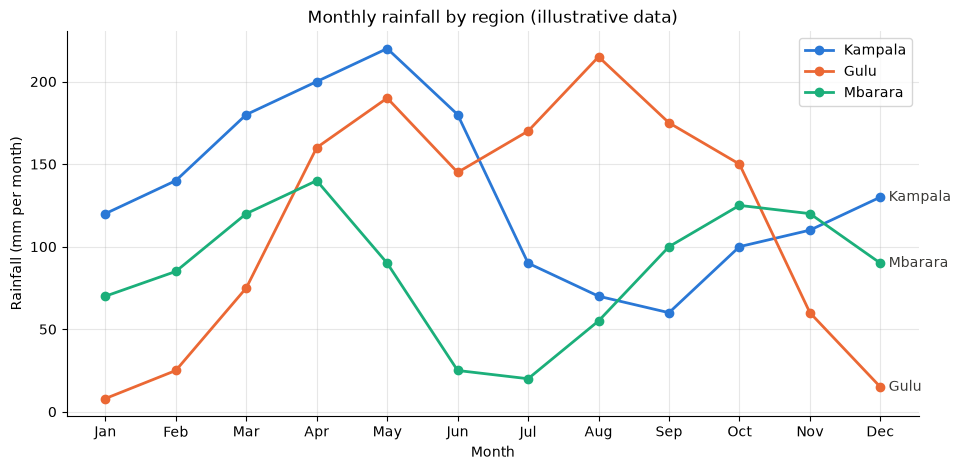

In [9]:
# (a) All regions' rainfall on one line chart
fig, ax = plt.subplots(figsize=(11, 5))
for r in regions:
    ax.plot(MONTHS, r.rainfall, "o-", lw=2, color=REGION_COLOURS[r.name], label=r.name)
    ax.annotate(r.name, (11, r.rainfall[-1]), xytext=(6, 0), textcoords="offset points",
                color=INK, va="center", fontsize=10)
ax.set_xlabel("Month")
ax.set_ylabel("Rainfall (mm per month)")
ax.set_title("Monthly rainfall by region (illustrative data)")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

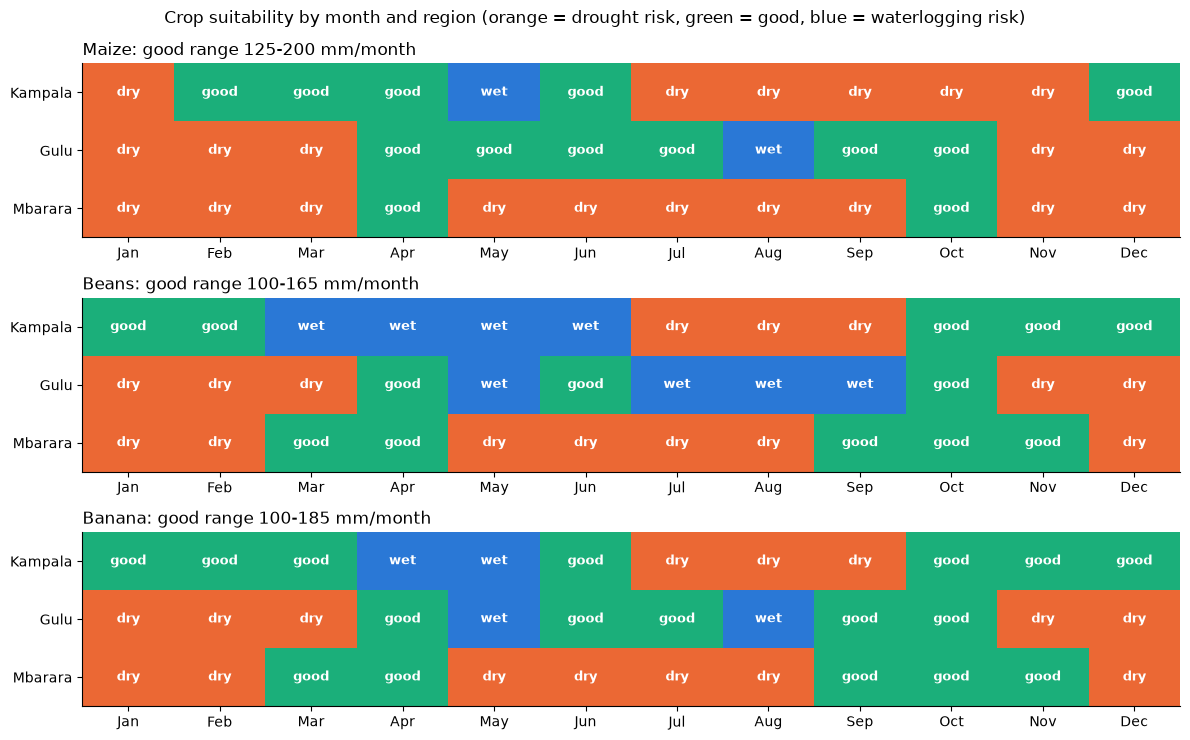

In [10]:
# (b) Heatmap of crop suitability: one panel per crop, rows = regions, columns = months
#     -1 = drought risk (orange), 0 = good (green), +1 = waterlogging risk (blue)
colour_map = ListedColormap(["#eb6834", "#1baf7a", "#2a78d6"])
text_for_score = {-1: "dry", 0: "good", 1: "wet"}

fig, axes = plt.subplots(len(crops), 1, figsize=(12, 7.5))
for ax, rule in zip(axes, crops):
    scores = np.array([[rule.score(mm) for mm in r.rainfall] for r in regions])
    ax.imshow(scores, cmap=colour_map, vmin=-1, vmax=1, aspect="auto")
    for row in range(scores.shape[0]):            # write the label in every cell
        for col in range(scores.shape[1]):
            ax.text(col, row, text_for_score[scores[row, col]], ha="center", va="center",
                    color="white", fontsize=9, fontweight="bold")
    ax.set_xticks(range(12), MONTHS)
    ax.set_yticks(range(len(regions)), [r.name for r in regions])
    ax.set_title(f"{rule.crop.capitalize()}: good range {rule.min_mm}-{rule.max_mm} mm/month", loc="left")
fig.suptitle("Crop suitability by month and region (orange = drought risk, green = good, blue = waterlogging risk)")
fig.tight_layout()
plt.show()

## Task 7 – Advisory note for farmers in Mbarara

**To farmers in Mbarara: what to plant, and when**

Mbarara has **two rainy seasons** a year: a first one from March to April and a second, slightly longer one from
September to November. Between them, May to August is dry, with only 20–25 mm of rain in June and July, and
December to February is also dry.

**Beans are the best fit.** Beans need about 100–165 mm of rain a month for roughly three months, and both of
Mbarara's seasons give exactly that. Plant your first crop at the **start of the March rains** (once the soil is moist,
usually early March) so it can be harvested in June as the dry season begins. Plant a second crop in **early
September**, for harvest in December.

**Bananas (matooke)** do well in the wet months, but will suffer from June to August. Mulch heavily around the
stems before June and, where you can, collect rainwater in April and October to water them in the dry months.

**Maize is risky here.** In most months Mbarara is drier than maize prefers. If you grow maize, plant a short-season,
drought-tolerant variety at the very start of the September rains, which are the more reliable season.

Rain varies a lot from year to year, so don't plant on the calendar date alone: wait for the first good rains and
check your local weather forecast.

## Extension – Real rainfall data: Kampala 2014–2023 (NASA POWER)

**Source:** NASA POWER, Prediction Of Worldwide Energy Resources (https://power.larc.nasa.gov), monthly
`PRECTOTCORR` (corrected precipitation, MERRA-2 reanalysis) at latitude 0.35, longitude 32.58 (Kampala), 2014–2023.
The file was downloaded once and saved to `data/nasa_power_kampala_2014_2023.csv`, so the notebook runs offline.
NASA gives mm **per day**. The loader multiplies by the days in each month to get mm per month.

In [11]:
real = load_nasa_power_csv("data/nasa_power_kampala_2014_2023.csv")   # rows = years, columns = months
real.round(0)

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
2014,51.0,30.0,129.0,239.0,219.0,89.0,59.0,94.0,165.0,212.0,120.0,129.0
2015,8.0,53.0,151.0,195.0,298.0,56.0,32.0,46.0,64.0,307.0,417.0,215.0
2016,63.0,32.0,115.0,248.0,185.0,49.0,28.0,53.0,100.0,151.0,112.0,77.0
2017,47.0,127.0,115.0,191.0,218.0,62.0,44.0,69.0,129.0,131.0,163.0,24.0
2018,34.0,53.0,184.0,256.0,115.0,47.0,26.0,76.0,190.0,110.0,191.0,131.0
2019,65.0,72.0,68.0,195.0,171.0,101.0,79.0,102.0,127.0,407.0,157.0,179.0
2020,91.0,130.0,283.0,170.0,165.0,68.0,37.0,73.0,111.0,139.0,265.0,138.0
2021,140.0,46.0,82.0,196.0,85.0,19.0,8.0,23.0,89.0,106.0,220.0,91.0
2022,47.0,45.0,231.0,135.0,129.0,62.0,40.0,106.0,111.0,180.0,203.0,152.0
2023,27.0,38.0,260.0,229.0,83.0,165.0,26.0,51.0,262.0,242.0,301.0,109.0


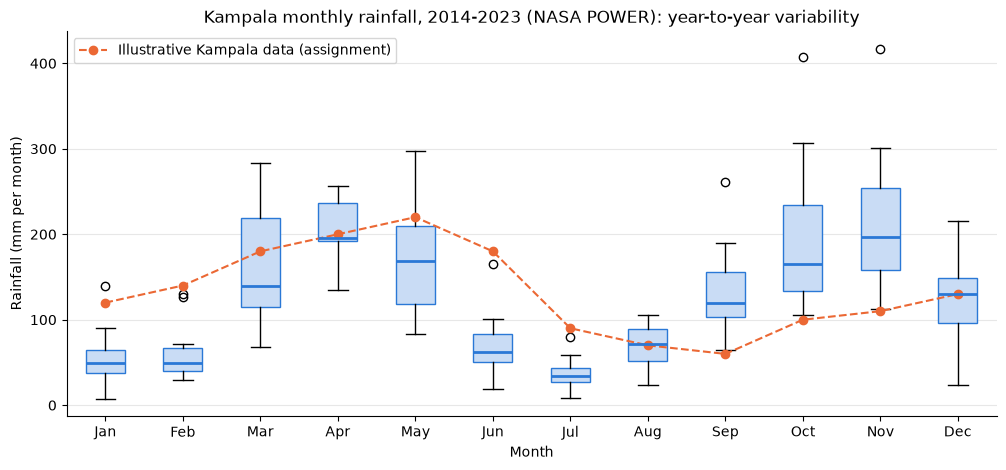

Real 10-year mean, annual total: 1506 mm
Rainy seasons in real mean: ['Apr', 'Nov'] -> bimodal


In [12]:
fig, ax = plt.subplots(figsize=(12, 5))
# One box per month: the box covers the middle 50% of years, the line is the median,
# the whiskers show the spread, dots are unusual years.
ax.boxplot([real[m] for m in MONTHS], tick_labels=MONTHS, patch_artist=True,
           boxprops={"facecolor": "#c9dcf5", "edgecolor": "#2a78d6"},
           medianprops={"color": "#2a78d6", "lw": 2})
ax.plot(range(1, 13), kampala.rainfall, "o--", color="#eb6834", label="Illustrative Kampala data (assignment)")
ax.set_xlabel("Month")
ax.set_ylabel("Rainfall (mm per month)")
ax.set_title("Kampala monthly rainfall, 2014-2023 (NASA POWER): year-to-year variability")
ax.grid(axis="y", alpha=0.3)
ax.legend()
plt.show()

real_region = Region("Kampala (NASA 10-yr mean)", real.mean().values)
print("Real 10-year mean, annual total:", round(real_region.annual_total()), "mm")
print("Rainy seasons in real mean:", rainy_seasons(real_region), "->", modality(real_region))

**What the real data shows.**

* The real 10-year average is clearly **bimodal**, with peaks in **April** and **November**, which matches Kampala's
  known climate. Our peak finder gets this right on real data, even though the illustrative numbers came out unimodal.
* The illustrative data is quite wrong for **January–February** (120–140 mm against about 50 mm in reality) and
  **October–November** (100–110 mm against about 170–200 mm). An advisory built on it would tell farmers to plant
  in a dry January and would underestimate the second season.
* The **boxes are tall**: the same month can be very different from one year to the next. October ranged from about
  106 mm (2021) to 407 mm (2019). March ranged from under 70 mm to over 280 mm. So a farmer faces much more risk than
  a single "average year" suggests, which is why the advisory note tells farmers to wait for the rains rather than
  plant by the calendar.

## Findings & Limitations

**Findings.** The three regions differ in both *how much* it rains and *when*. Kampala is the wettest (1,600 mm),
Mbarara the driest (1,040 mm), and Gulu the most seasonal (CV 0.64), with a near-rainless November–March.
The similarity measures disagree in an instructive way. Cosine similarity rates every pair as quite similar
(0.75–0.89), yet Pearson correlation is close to zero or negative. Gulu is at its wettest in August, when Kampala is
nearly at its driest. Cosine is fooled because all rainfall vectors are positive and "point" in broadly the same
direction. For advice about *timing*, correlation is the more honest measure. For *amount*, only Euclidean distance helps.

For crops, Gulu offers one long continuous window (April–October is good for maize in 6 of 7 months). Mbarara
offers two short windows (March–April and September–November) suited to beans and bananas but mostly too dry for
maize. In Kampala, March–June is actually *too wet* for beans under our rule.

The real NASA data changes the picture of Kampala: January–February are much drier (about 50 mm, not 120 mm), the
second season (Oct–Nov) is the wettest, and the pattern is clearly bimodal. It also shows large year-to-year swings
(October ranged from about 106 to 407 mm). Advice built on average months hides that risk.

**Limitations.** Our monthly crop ranges come from dividing FAO seasonal totals by season length. Real needs vary by
growth stage, and soil, temperature and the spread of rain *within* a month are ignored. The 20 mm prominence
threshold is a choice, and it changed Kampala's classification. The illustrative data does not match the real
climate well. NASA POWER is gridded reanalysis (~50 km cells), not a rain gauge.